# HW5 : 전처리 재현 + 질문 셋
- 이름 : 김준혁
- 학번 : 22011645
- 입력 : `sales_data.csv` (집현캠퍼스) / 출력 : `sales_clean.csv`

In [1]:
import platform
import pandas as pd
import matplotlib.pyplot as plt

# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

## 단계 ① 읽고, 날짜 세 칸을 날짜로

In [2]:
df = pd.read_csv("sales_data.csv")
for col in ["order_date", "shipping_date", "delivery_date"]:
    df[col] = pd.to_datetime(df[col])
print(df.shape)   # (1030, 14) 이어야 함

(1030, 14)


## 단계 ② 중복 행 제거

In [3]:
before = len(df)
df = df.drop_duplicates()   # df = 로 다시 받아야 반영됨
print(before, "->", len(df))   # 1030 -> 1004 이어야 함

1030 -> 1004


## 단계 ③ 수량 > 100 인 줄의 수량을 금액 ÷ 단가로 복원

In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())
# 고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0 이어야 함

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


## 단계 ④ date_error 표시 추가, sales_clean.csv 저장

In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print(df["date_error"].sum(), "건,", df.shape)   # 147 건, (1004, 15) 이어야 함
df.to_csv("sales_clean.csv", index=False)

147 건, (1004, 15)


## 단계 ⑤ 질문 : 배송 기간(도착일 − 배송일)은 보통 며칠인가

줄 수 : 852  평균 : 22.1  중앙값 : 2.0


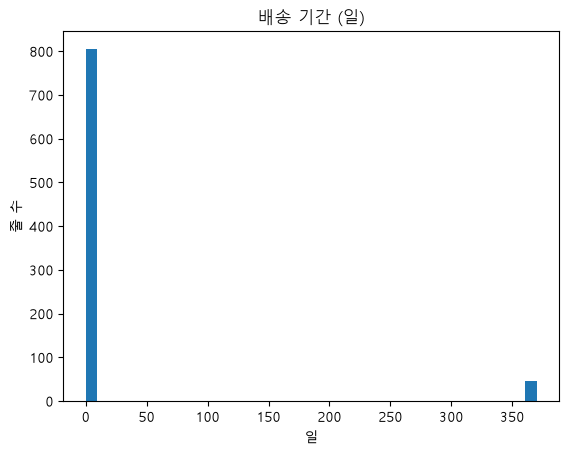

In [6]:
ok = df[~df["date_error"]]                      # date_error 가 아닌 줄만
days = (ok["delivery_date"] - ok["shipping_date"]).dt.days.dropna()
print("줄 수 :", len(days), " 평균 :", round(days.mean(), 1), " 중앙값 :", days.median())
days.plot.hist(bins=40, title="배송 기간 (일)")
plt.xlabel("일"); plt.ylabel("줄 수")
plt.show()

In [7]:
# 오른쪽 끝 덩어리를 들여다본다
print("300일 넘는 줄 :", (days > 300).sum())
print(days[days > 300].describe())
ok.loc[days[days > 300].index, ["order_date", "shipping_date", "delivery_date"]].head()

300일 넘는 줄 : 47
count     47.000000
mean     366.638298
std        1.798859
min      364.000000
25%      365.000000
50%      367.000000
75%      368.000000
max      370.000000
dtype: float64


,order_date,shipping_date,delivery_date
11,2023-01-12,2023-01-15,2024-01-15
20,2023-01-21,2023-01-23,2024-01-27
29,2023-01-30,2023-02-03,2024-02-03
41,2023-02-11,2023-02-14,2024-02-17
68,2023-03-10,2023-03-14,2024-03-12


처리 후 줄 수 : 805  평균 : 1.9  중앙값 : 2.0


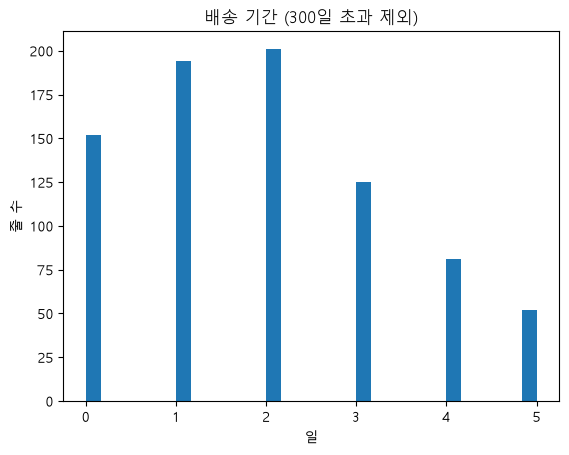

In [8]:
# 결정 : 어떻게 할지는 위 표를 보고 직접 정할 것 (아래는 「300일 넘는 줄은 빼고 센다」 예시)
days_clean = days[days <= 300]
print("처리 후 줄 수 :", len(days_clean), " 평균 :", round(days_clean.mean(), 1), " 중앙값 :", days_clean.median())
days_clean.plot.hist(bins=30, title="배송 기간 (300일 초과 제외)")
plt.xlabel("일"); plt.ylabel("줄 수")
plt.show()

- 도착일이 빈 5줄과 날짜 오류 147줄을 뺀 852줄 기준 배송 기간은 중앙값 2일, 평균 22.1일로 크게 다르다. 평균이 큰 값에 끌려 올라간 것이다.
- 원인은 364~370일(배송일의 약 1년 뒤)인 47줄이다. 이 줄을 빼면 805줄의 평균 1.9일, 중앙값 2일이고 덩어리 밖 최대는 5일이다. 연도 입력 오류를 가정하더라도 도착일에서 1년을 빼도 7줄이 음수(−2~−1일)가 되어 깨끗하게 복원되지 않고, 어느 칸이 틀렸는지 판단할 근거가 없어 고치지 않고 이 질문에서만 제외했다.

## 단계 ⑥ 질문 : 만족도가 낮을수록 반품이 많은가

satisfaction
1     7.6
2    12.0
3     7.8
4     8.7
5     6.9
Name: status, dtype: float64


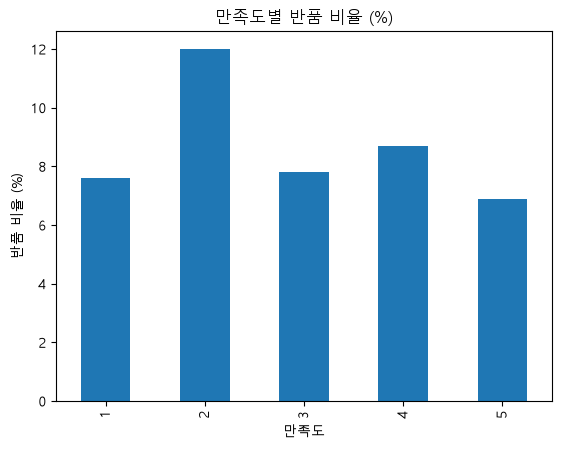

In [9]:
returned = (df["status"] == "반품")
rate = (returned.groupby(df["satisfaction"]).mean() * 100).round(1)
rate.index = rate.index.astype(int)
print(rate)
rate.plot.bar(title="만족도별 반품 비율 (%)")
plt.xlabel("만족도"); plt.ylabel("반품 비율 (%)")
plt.show()

- 아니다. 만족도가 빈 30줄을 뺀 974줄 기준 만족도별 반품 비율은 1점 7.6%, 2점 12.0%, 3점 7.8%, 4점 8.7%, 5점 6.9%로, 만족도가 낮을수록 늘어나는 흐름이 없다 (전체 8.6%, 만족도와 반품의 상관 −0.02).
- 가장 높은 것은 1점이 아니라 2점(12.0%)이고, 1점(7.6%)은 3점(7.8%)과 비슷하다. 칸마다 반품이 14~22건뿐이라 이 차이를 뚜렷한 경향이라고 보기는 어렵다.

## 단계 ⑦ 질문 : 카테고리 매출 1위의 이유는 건수 · 단가 · 수량 중 무엇인가

In [10]:
by_cat = df.groupby("category").agg(
    건수=("category", "size"),
    매출합=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean"),
).sort_values("매출합", ascending=False).round(1)
by_cat

,건수,매출합,평균단가,평균수량
category,,,,
가구,213,2.843337e+09,257322.9,51.0
식품,210,2.513274e+09,255232.9,47.3
전자제품,207,2.471628e+09,249651.6,48.0
도서,204,2.453240e+09,238500.6,49.5
의류,170,2.181904e+09,249447.2,51.6


- 매출 1위는 가구(약 28.4억 원)로, 2위 식품(약 25.1억 원)보다 13.1% 많다.
- 1위 가구는 식품보다 건수 +1.4%(213 대 210건), 평균 단가 +0.8%(257,323 대 255,233원), 평균 수량 약 +8%(51.0 대 47.3개) 높다. 차이가 가장 크게 나는 칸은 평균 수량이다. 다만 평균 수량 1위는 의류(51.6개)라서 가구가 수량에서 1등인 것은 아니다.